# 02. Baselines and errors

Results of the first full run. Commands that produce the files are in the README. Nothing here is computed on the fly: the notebook reads `results/metrics/`.

In [1]:
import csv, json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

ROOT = Path("..").resolve()
PALETTE = np.array([(240,234,222),(214,178,112),(92,64,51),(196,78,56),(58,90,120)], np.uint8)
CLASSES = ["background", "floor", "wall", "installation", "pit"]
load = lambda p: json.loads((ROOT / p).read_text(encoding="utf-8"))

## 1. Extraction: language model against the reference layouts

In [2]:
err = load("results/metrics/error_analysis.json")
for k in ("extraction_opus", "extraction_sonnet"):
    print(k); print(json.dumps(err[k], indent=1))

extraction_opus
{
 "n_reports": 8,
 "relations_strict": {
  "tp": 41,
  "pred": 53,
  "gold": 52,
  "precision": 0.77358,
  "recall": 0.78846
 },
 "relations_canonical": {
  "tp": 42,
  "pred": 53,
  "gold": 52,
  "precision": 0.79245,
  "recall": 0.80769
 },
 "missed_relations": {
  "adjacent_to": 4,
  "west_of": 3,
  "inside": 2,
  "north_of": 1
 },
 "extra_relations": {
  "north_of": 5,
  "adjacent_to": 2,
  "west_of": 2,
  "inside": 2
 },
 "centre_offset_m": {
  "median": 0.2,
  "p90": 0.74,
  "max": 1.281,
  "floor": 0.2,
  "installation": 0.51,
  "pit": 0.2,
  "wall": 0.241
 },
 "box_iou": {
  "mean": 0.589,
  "floor": 0.848,
  "installation": 0.434,
  "pit": 0.555,
  "wall": 0.513
 }
}
extraction_sonnet
{
 "n_reports": 8,
 "relations_strict": {
  "tp": 39,
  "pred": 41,
  "gold": 52,
  "precision": 0.95122,
  "recall": 0.75
 },
 "relations_canonical": {
  "tp": 39,
  "pred": 41,
  "gold": 52,
  "precision": 0.95122,
  "recall": 0.75
 },
 "missed_relations": {
  "west_of": 5,
  "

## 2. Generation: text only, hand-built layout, LLM layout, GLIGEN

In [3]:
print((ROOT / "03_controlled_generation/outputs/summary.md").read_text(encoding="utf-8").split("## ")[2][:900])
print(json.dumps({k: {a: b for a, b in v.items() if a != "pits_counted_as_drawn"} for k, v in err["generation"].items()}, indent=1)[:3000])

רזולוציה: coarse

| תנאי | HOR ↓ | HOR_area ↓ | Object Recall ↑ | HAR ↓ | רכיבים זרים ↓ |
|---|---|---|---|---|---|
| gligen | 0.763 | 0.787 | 0.497 | 0.569 | 3.850 |
| photo | 0.625 | 0.729 | 0.632 | 0.640 | 2.100 |
| photo_bgsand | 0.593 | 0.771 | 0.642 | 0.772 | 1.650 |
| photo_llm | 0.730 | 0.777 | 0.482 | 0.658 | 2.600 |
| photo_textonly | 0.823 | 0.775 | 0.203 | 0.219 | 0.650 |
| schematic ⚠ לא תקף | 0.706 | 0.814 | 0.578 | 0.984 | 6.100 |

השוואה מזווגת: **gligen** מול **photo_textonly** (אותו Layout ואותו seed, 20 זוגות). מספר הזוגות שבהם gligen טוב יותר:

- HOR: 14 מתוך 20 (שוויון: 2)
- HOR_area: 12 מתוך 20
- object_recall: 14 מתוך 20 (שוויון: 3)
- HAR: 4 מתוך 20

השוואה מזווגת: **photo** מול **photo_textonly** (אותו Layout ואותו seed, 20 זוגות). מספר הזוגות שבהם photo טוב יותר:

- HOR: 17 מתוך 20
- HOR_area: 15 מתוך 20
- object_recall: 17 מתוך 20 (שוויון: 3)
- HAR: 3 מתוך 20

ה
{
 "photo": {
  "n_images": 20,
  "images_with_invented_wall": 20,
  "images_with_foreign_content":

The first lens of the research question is the mIoU to the text layout (`results/metrics/pilot_miou.json`).

In [4]:
pm = load("results/metrics/pilot_miou.json")
for k, v in pm["conditions"].items():
    print(f"{k:16s} mIoU {v['miou']:.3f}  minus text only {v['minus_text_only']:+.3f}  higher in {v['n_higher']} of {pm['n_cases']} cases  IoU by class {v['iou_by_class']}")

photo_textonly   mIoU 0.306  minus text only +0.000  higher in 0 of 5 cases  IoU by class {'ground': 0.6725, 'built': 0.0962, 'pit': 0.0}
gligen           mIoU 0.221  minus text only -0.085  higher in 1 of 5 cases  IoU by class {'ground': 0.4006, 'built': 0.169, 'pit': 0.0394}
photo            mIoU 0.224  minus text only -0.082  higher in 1 of 5 cases  IoU by class {'ground': 0.3427, 'built': 0.2074, 'pit': 0.0}
photo_llm        mIoU 0.188  minus text only -0.118  higher in 1 of 5 cases  IoU by class {'ground': 0.3112, 'built': 0.1445, 'pit': 0.0}


**Reading.** More of the layout is drawn with a layout than with text only, and the mIoU falls: the IoU of built things rises and the IoU of the ground falls, because the generator fills empty ground with walls. Five cases are descriptive only.

## 3. Segmentation on the generated test set

majority_background 0.0978 [0.0776, 0.1179] {'background': 0.4891, 'floor': 0.0, 'wall': 0.0, 'installation': 0.0, 'pit': 0.0}
segformer_ade 0.1328 [0.1111, 0.1537] {'background': 0.4152, 'floor': 0.0003, 'wall': 0.2477, 'installation': 0.0003, 'pit': 0.0003}
grounded_sam 0.1307 [0.1104, 0.1511] {'background': 0.3738, 'floor': 0.1038, 'wall': 0.0194, 'installation': 0.0213, 'pit': 0.1351}
unet_synth 0.6039 [0.5536, 0.6506] {'background': 0.6517, 'floor': 0.5466, 'wall': 0.7968, 'installation': 0.3563, 'pit': 0.6681}
{'unet_synth - grounded_sam': {'delta_miou': 0.4732, 'ci95': [0.4175, 0.5245]}}


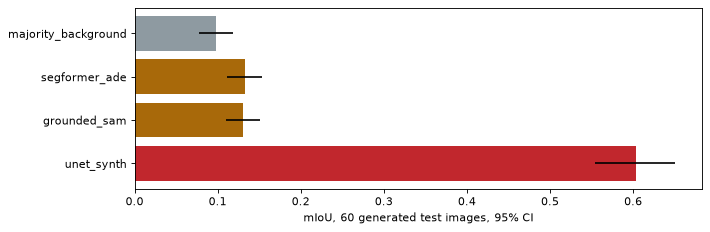

In [5]:
S = load("results/metrics/synth_test.json")
m = S["models"]
fig, ax = plt.subplots(figsize=(9, 3))
n = list(m); v = [m[k]["miou"] for k in n]; lo = [m[k]["miou"] - m[k]["miou_ci95"][0] for k in n]; hi = [m[k]["miou_ci95"][1] - m[k]["miou"] for k in n]
ax.barh(n, v, xerr=[lo, hi], color=["#8E9AA1", "#A8690A", "#A8690A", "#C1272D"]); ax.invert_yaxis(); ax.set_xlabel("mIoU, 60 generated test images, 95% CI"); plt.tight_layout(); plt.show()
for k in n: print(k, m[k]["miou"], m[k]["miou_ci95"], m[k]["iou_per_class"])
print(S["paired"])

The labels of this set are the masks given to the generator, so a high score means the network reproduces the generator's mask. It does not show quality on real photos, and it is optimistic: 59 of 60 test images share a diffusion seed with training images. The zero-shot models run with default settings here.

## 4. Walls on real drone tiles

all_wall           {'iou': 0.1153, 'iou_ci95': [0.0891, 0.1368], 'precision': 0.1153, 'recall': 1.0, 'f1': 0.2067, 'iou_per_seed': [0.1153]}
bright_texture     {'iou': 0.2959, 'iou_ci95': [0.2446, 0.3435], 'precision': 0.3976, 'recall': 0.5362, 'f1': 0.4566, 'iou_per_seed': [0.2959]}
segformer_ade      {'iou': 0.1244, 'iou_ci95': [0.0559, 0.2028], 'precision': 0.2457, 'recall': 0.2013, 'f1': 0.2213, 'iou_per_seed': [0.1244]}
grounded_sam       {'iou': 0.1832, 'iou_ci95': [0.132, 0.2415], 'precision': 0.2356, 'recall': 0.4514, 'f1': 0.3096, 'iou_per_seed': [0.1832]}
unet_synth         {'iou': 0.0, 'iou_ci95': [0.0, 0.0], 'precision': 0.0025, 'recall': 0.0, 'f1': 0.0, 'iou_per_seed': [0.0, 0.0, 0.0]}
unet_real          {'iou': 0.4388, 'iou_ci95': [0.4018, 0.4792], 'precision': 0.607, 'recall': 0.6156, 'f1': 0.61, 'iou_per_seed': [0.4284, 0.443, 0.4451]}
unet_synth_real    {'iou': 0.4223, 'iou_ci95': [0.385, 0.4627], 'precision': 0.6272, 'recall': 0.5638, 'f1': 0.5938, 'iou_per_seed': [0.

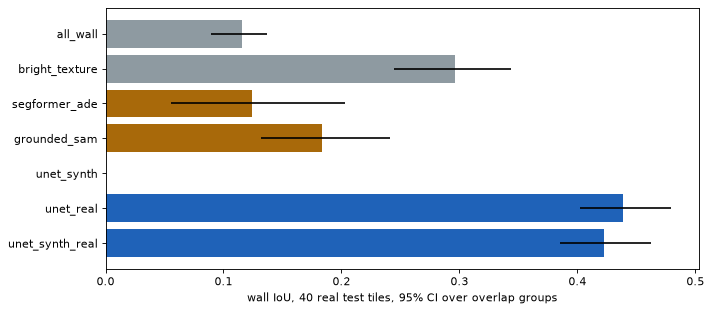

In [6]:
W = load("results/metrics/real_walls.json")
m = W["models"]
fig, ax = plt.subplots(figsize=(9, 4))
n = list(m); v = [m[k]["iou"] for k in n]; lo = [m[k]["iou"] - m[k]["iou_ci95"][0] for k in n]; hi = [m[k]["iou_ci95"][1] - m[k]["iou"] for k in n]
ax.barh(n, v, xerr=[lo, hi], color=["#8E9AA1", "#8E9AA1", "#A8690A", "#A8690A", "#C1272D", "#1F62B8", "#1F62B8"]); ax.invert_yaxis(); ax.set_xlabel("wall IoU, 40 real test tiles, 95% CI over overlap groups"); plt.tight_layout(); plt.show()
for k in n: print(f"{k:18s}", {a: m[k][a] for a in ("iou", "iou_ci95", "precision", "recall", "f1", "iou_per_seed")})
print(json.dumps(W["paired"], indent=1)); print(json.dumps(W["selected_on_dev"], indent=1))

## 5. Where the errors are

In [7]:
print(json.dumps(err["real_walls"], indent=1))

{
 "all_wall": {
  "nonwall_area_share": {
   "vegetation": 0.219,
   "shadow": 0.1,
   "bright stone or rock": 0.211,
   "soil and rubble": 0.47
  },
  "false_positive_rate_by_surface": {
   "vegetation": 1.0,
   "shadow": 1.0,
   "bright stone or rock": 1.0,
   "soil and rubble": 1.0
  },
  "false_positive_share": {
   "vegetation": 0.219,
   "shadow": 0.1,
   "bright stone or rock": 0.211,
   "soil and rubble": 0.47
  },
  "false_negative_share": {
   "vegetation": 0.0,
   "shadow": 0.0,
   "bright stone or rock": 0.0,
   "soil and rubble": 0.0
  },
  "wall_recall_by_surface": {
   "vegetation": 1.0,
   "shadow": 1.0,
   "bright stone or rock": 1.0,
   "soil and rubble": 1.0
  },
  "wall_share_of_surface": {
   "vegetation": 0.019,
   "shadow": 0.092,
   "bright stone or rock": 0.235,
   "soil and rubble": 0.098
  },
  "wall_pixels_by_surface": {
   "vegetation": 0.032,
   "shadow": 0.078,
   "bright stone or rock": 0.497,
   "soil and rubble": 0.393
  }
 },
 "bright_texture": {
  "

Examples on four test tiles. Green: wall found. Red: predicted but not labelled. Yellow: missed.

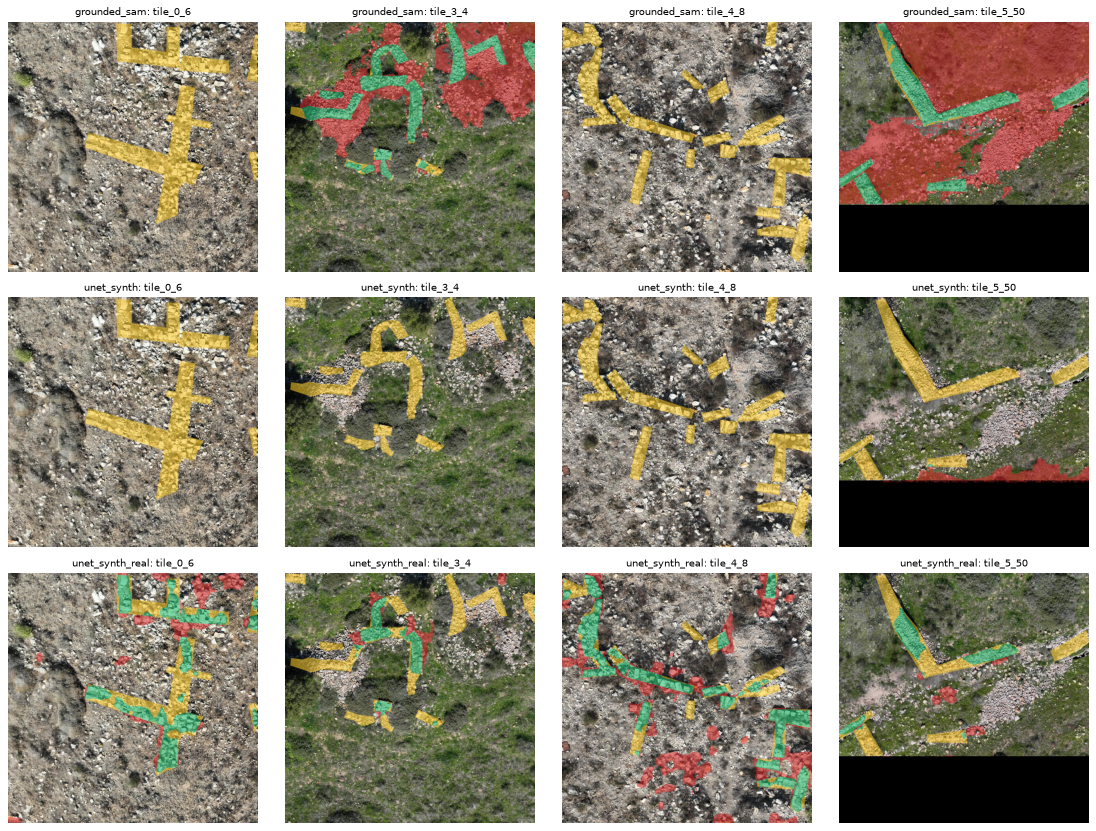

In [8]:
def overlay(tile, model):
    base = ROOT / "04_cv_experiment/data/real/walls/test"
    a = np.array(Image.open(base / f"images/{tile}.png").convert("RGB")).astype(float)
    g = np.array(Image.open(base / f"masks/{tile}.png")); p = np.array(Image.open(ROOT / f"results/predictions/real_walls/{model}/{tile}.png")) > 127
    for m, c in (((g == 2) & p, (30,190,110)), ((g == 0) & p, (214,40,40)), ((g == 2) & ~p, (255,205,40))): a[m] = .45 * a[m] + .55 * np.array(c)
    return a.astype(np.uint8)
tiles = [r["tile"] for r in csv.DictReader(open(ROOT / "results/metrics/real_walls_per_tile.csv")) if r["model"] == "unet_synth_real"]
pick = tiles[::max(1, len(tiles) // 4)][:4]
fig, ax = plt.subplots(3, 4, figsize=(14, 10.5))
for i, mod in enumerate(("grounded_sam", "unet_synth", "unet_synth_real")):
    for j, t in enumerate(pick):
        ax[i, j].imshow(overlay(t, mod)); ax[i, j].set_title(f"{mod}: {t}", fontsize=9); ax[i, j].axis("off")
plt.tight_layout(); plt.show()